# CDS 303 Final Project 2 — Portable Notebook

**Team:** Seohyun Hong, Sieun Woo, Seoyoung Yun  
**Primary source:** NYC Inside Airbnb listings (September 14, 2026)  
**Scope:** Data integration, refined research question, and Demo 06 PCA. No clustering/classification.

## Place all input CSVs in the SAME folder as this Jupyter notebook

`listings.csv`, `calendar.csv`, `commonplace.csv`, `subway.csv`,
`airports.csv`, `restaurants.csv`, `nypd.csv`, `311.csv`.

Extra suffixes like `(1)`, `(2)`, `(4)` are duplicate downloads: keep one copy
per dataset and use the single name above. Open and run the notebook from
this folder. **No personal/absolute file paths are needed.**

The notebook automatically creates `data/` for output CSVs and `figures/`
for saved plots. These are output folders, NOT folders for raw CSV inputs.

Steps 1–17: understand, clean, and integrate all data. Steps 18–25: question,
audience, PCA (as in Demo 06), explained variance, loadings and biplot.


## Step 1. Import libraries

We use the same basic `numpy`, `pandas`, `matplotlib`, `seaborn` format as the professor's demo. `BallTree` is only for matching nearby locations; it is **not PCA**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings(action = 'ignore')

# Additional tool for joining records by distance
from pathlib import Path

# Folders for generated results only (created automatically)
Path('data').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

from sklearn.neighbors import BallTree

## Step 2. Load our primary Airbnb dataset

**`df` is the original primary dataset.** `id` identifies a listing; `host_id` is not unique. `listings(4).csv` is just another copy of `listings.csv`, so we load only **one file**.

In [2]:
df = pd.read_csv('listings.csv', low_memory = False)
print('Rows and columns:', df.shape)
print('Unique listing IDs:', df['id'].is_unique)
df.head()

Rows and columns: (29918, 90)
Unique listing IDs: True


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1352055619826961511,https://www.airbnb.com/rooms/1352055619826961511,20260914002229,2026-09-14,NaN,"New 3 bed, 1.5 bath",This stylish place to stay is perfect for grou...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,677651543,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,1215930899551057941,https://www.airbnb.com/rooms/1215930899551057941,20260914002229,2026-09-14,NaN,Queens apartament,Bring the whole family to this great place wit...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,392517036,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,1203866180302079266,https://www.airbnb.com/rooms/1203866180302079266,20260914002229,2026-09-15,NaN,Luxury Meets Comfort Stay NYC,This stylish place is close to must-see destin...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,115082911,...,NaN,NaN,NaN,NaN,NaN,2,0,2,0,NaN
3,15310580,https://www.airbnb.com/rooms/15310580,20260914002229,2026-09-15,previous scrape,Nice apartment in Gramercy.,Nice apartment in one of the best neighbors of NY,NaN,https://a0.muscache.com/pictures/c2c78aad-78c9...,27336207,...,4.88,5.00,4.25,NaN,NaN,2,2,0,0,0.07
4,32842295,https://www.airbnb.com/rooms/32842295,20260914002229,2026-09-15,previous scrape,Beautiful bedroom and full bathroom,NaN,NaN,https://a0.muscache.com/pictures/b946d6e3-07d6...,233227636,...,4.89,4.78,4.75,NaN,NaN,1,0,1,0,0.40


## Step 3. Check the original Project 1 variables

The first four are our original listing characteristics. The other four are useful for later comparisons, but are not used as numerical IDs in PCA.

In [3]:
clustering_vars = ['price', 'availability_30', 'availability_365', 'minimum_nights']
classification_vars = ['room_type', 'neighbourhood_group_cleansed',
                       'calculated_host_listings_count', 'license']
print(df[clustering_vars + classification_vars].dtypes)
df[clustering_vars + classification_vars].head()

price                                 str
availability_30                     int64
availability_365                    int64
minimum_nights                    float64
room_type                             str
neighbourhood_group_cleansed          str
calculated_host_listings_count      int64
license                               str
dtype: object


,price,availability_30,availability_365,minimum_nights,room_type,neighbourhood_group_cleansed,calculated_host_listings_count,license
0,NaN,30,365,30.0,Entire home/apt,Brooklyn,1,NaN
1,$164.55,29,364,31.0,Private room,Queens,1,NaN
2,NaN,30,269,30.0,Private room,Brooklyn,2,NaN
3,NaN,0,0,30.0,Entire home/apt,Manhattan,2,NaN
4,NaN,0,0,80.0,Private room,Brooklyn,1,NaN


## Step 4. Convert price to a number (Project 1 method)

The original price column includes dollar signs and commas. We convert it, but never replace missing prices with zero.

In [4]:
df['price_num'] = pd.to_numeric(
    df['price'].astype('string').str.replace(r'[\$,]', '', regex = True),
    errors = 'coerce'
)
df[['price', 'price_num']].head(10)

,price,price_num
0,NaN,<NA>
1,$164.55,164.55
2,NaN,<NA>
3,NaN,<NA>
4,NaN,<NA>
5,NaN,<NA>
6,NaN,<NA>
7,$236.00,236.0
8,$143.47,143.47
9,$102.97,102.97


## Step 5. Check missing values

Our Project 1 showed that many prices are missing. Print both the number and percentage of missing values, and check how missing prices relate to annual availability.

In [5]:
basic_cols = ['price_num', 'availability_30', 'availability_365', 'minimum_nights']
missing = pd.DataFrame({
    'Missing Count': df[basic_cols].isna().sum(),
    'Missing %': (df[basic_cols].isna().mean() * 100).round(1)
})
print(missing)
print(pd.crosstab(df['availability_365'] == 0, df['price_num'].isna()))

                  Missing Count  Missing %
price_num                 10512       35.1
availability_30               0        0.0
availability_365              0        0.0
minimum_nights                8        0.0
price_num         False  True 
availability_365              
False             19397   3503
True                  9   7009


## Step 6. Summary statistics and simple graphs

This helps us understand price ranges and unusual values before integrating any new source. High prices do not automatically mean errors.

       price_num  availability_30  availability_365  minimum_nights
count    19406.0          29918.0           29918.0         29910.0
mean       310.2              9.4             188.8            26.8
std        574.1             11.7             140.5            28.5
min         17.7              0.0               0.0             1.0
25%        103.7              0.0              14.0            30.0
50%        182.4              2.0             227.0            30.0
75%        337.0             19.0             323.0            30.0
max      31537.8             30.0             365.0          1124.0
99th percentile price: 2000.0


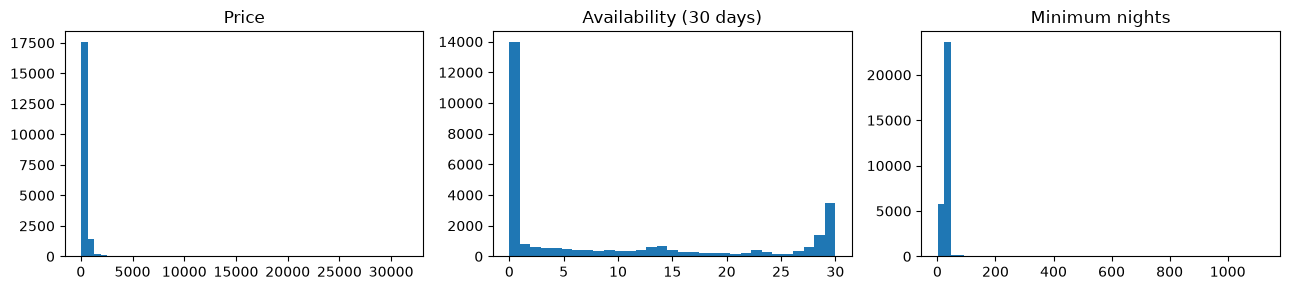

In [6]:
print(df[basic_cols].describe().round(1))
print('99th percentile price:', df['price_num'].quantile(.99))

fig, axes = plt.subplots(1, 3, figsize = (13, 3))
axes[0].hist(df['price_num'].dropna(), bins = 50)
axes[0].set_title('Price')
axes[1].hist(df['availability_30'], bins = 31)
axes[1].set_title('Availability (30 days)')
axes[2].hist(df['minimum_nights'].dropna(), bins = 50)
axes[2].set_title('Minimum nights')
plt.tight_layout()
plt.savefig('figures/airbnb_distributions.png', dpi = 150)
plt.show()

## Step 7. Start a one-listing-per-row table

Keep listing `id`, coordinates, and useful listing attributes. Coordinates are for joining nearby records. Remove obviously invalid geographic coordinates. We will always check that `id` stays unique.

In [7]:
cols = ['id', 'latitude', 'longitude', 'price_num', 'availability_30',
        'availability_365', 'minimum_nights', 'room_type',
        'neighbourhood_group_cleansed', 'calculated_host_listings_count', 'license']
combined = df[cols].copy()
combined = combined.rename(columns={'latitude':'Latitude', 'longitude':'Longitude'})
combined = combined[
    combined['Latitude'].between(40.3, 41.1) &
    combined['Longitude'].between(-74.4, -73.4)
].copy()
print('Listings after coordinate check:', combined.shape)
print('Unique listing IDs:',combined['id'].is_unique)

Listings after coordinate check: (29918, 11)
Unique listing IDs: True


## Step 8. Calendar data — why aggregation is necessary

Each calendar row represents **a listing on one date**, so directly merging it would repeat listing rows. Because the file is large, we read it in smaller chunks. We create weekday and weekend available-date rates by `listing_id` and only then merge. `available=f` may mean booked **or** blocked, not necessarily an actual booking.

In [8]:
calendar_parts = []
for chunk in pd.read_csv('calendar.csv',
                         usecols=['listing_id', 'date', 'available'],
                         chunksize=500000):
    chunk['weekend'] = pd.to_datetime(chunk['date']).dt.dayofweek >= 5
    chunk['open'] = (chunk['available'] == 't').astype(int)
    part = chunk.groupby(['listing_id', 'weekend'])['open'].agg(['sum', 'count'])
    calendar_parts.append(part)

calendar_sum = pd.concat(calendar_parts).groupby(level=[0,1]).sum().reset_index()
print('Number of listing/weekend groups:', len(calendar_sum))
calendar_sum.head()

Number of listing/weekend groups: 59836


,listing_id,weekend,sum,count
0,2539,False,226,261
1,2539,True,92,104
2,6848,False,202,261
3,6848,True,82,104
4,6872,False,247,261


In [9]:
calendar_wide = calendar_sum.pivot(index='listing_id', columns='weekend',
                                    values=['sum', 'count']).fillna(0)
calendar_wide.columns = ['_'.join([a, 'weekend' if b else 'weekday'])
                         for a, b in calendar_wide.columns]
calendar_wide = calendar_wide.reset_index()
calendar_wide['weekday_availability_rate'] = (
    calendar_wide['sum_weekday'] / calendar_wide['count_weekday'])
calendar_wide['weekend_availability_rate'] = (
    calendar_wide['sum_weekend'] / calendar_wide['count_weekend'])

calendar_summary = calendar_wide[['listing_id', 'weekday_availability_rate',
                                  'weekend_availability_rate']]
print('Unique calendar listing IDs:',calendar_summary['listing_id'].is_unique)
combined = combined.merge(calendar_summary, left_on='id', right_on='listing_id',
                          how='left', validate='one_to_one')
print('Rows after calendar merge:',len(combined))

Unique calendar listing IDs: True
Rows after calendar merge: 29918


## Step 9. Define a simple distance-matching function

Outside datasets have no Airbnb ID. We use lat/lon and count records in a circle around each listing. The distance radius is in **meters**. We also need a nearest-distance function for subway and airports.

In [10]:
listing_points = np.radians(combined[['Latitude','Longitude']].to_numpy())
earth_radius = 6371000

def clean_locations(data):
    data = data.copy()
    data['Latitude'] = pd.to_numeric(data['Latitude'], errors='coerce')
    data['Longitude'] = pd.to_numeric(data['Longitude'], errors='coerce')
    return data[data['Latitude'].between(40.3,41.1) &
                data['Longitude'].between(-74.4,-73.4)].copy()

def count_nearby(data, radius):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    return tree.query_radius(listing_points, r=radius/earth_radius, count_only=True)

def nearest_km(data):
    tree = BallTree(np.radians(data[['Latitude','Longitude']]), metric='haversine')
    distance, index = tree.query(listing_points, k=1)
    return distance[:,0]*earth_radius/1000

## Step 10. CommonPlace — parks and museums

`the_geom` is a WKT string `POINT (longitude latitude)`. Read those two numbers. `PLACEID` identifies a facility. The CommonPlace pair `(FACILITY TYPE, FACILITY DOMAINS) = (4,1)` is used for parks and `(3,4)` for museums (verified from facility names). Count each kind within **1 km**.

In [11]:
common = pd.read_csv('CommonPlace_20261109.csv',
                     usecols=['PLACEID','the_geom','FACILITY TYPE','FACILITY DOMAINS'])
common = common.drop_duplicates('PLACEID')
points = common['the_geom'].str.extract(r'POINT\s*\(\s*([-\d.]+)\s+([-\d.]+)\s*\)')
common['Longitude'] = pd.to_numeric(points[0],errors='coerce')
common['Latitude'] = pd.to_numeric(points[1],errors='coerce')
common = clean_locations(common)

parks = common[(common['FACILITY TYPE']==4) & (common['FACILITY DOMAINS']==1)]
museums = common[(common['FACILITY TYPE']==3) & (common['FACILITY DOMAINS']==4)]
combined['parks_1km'] = count_nearby(parks, 1000)
combined['museums_1km'] = count_nearby(museums, 1000)
print('Parks:',len(parks),'Museums:',len(museums))

Parks: 1274 Museums: 95


## Step 11. MTA subway — nearest station distance

`Complex ID` identifies a subway station complex, so we keep one record per complex. Measure kilometers to the nearest complex.

In [12]:
subway = pd.read_csv('MTA_Subway_Stations_and_Complexes_20261117.csv',
                     usecols=['Complex ID','Latitude','Longitude'])
subway = subway.drop_duplicates('Complex ID')
subway = clean_locations(subway)
combined['subway_distance_km'] = nearest_km(subway)
print('Subway complexes:',len(subway))

Subway complexes: 445


## Step 12. Airports — nearest NYC-serving airport distance

Use JFK, LGA, and EWR. EWR is outside NYC but it also serves travelers to the NYC area.

In [13]:
airports = pd.read_csv('nyc_airports.csv')
airports = airports[airports['iata_code'].isin(['JFK','LGA','EWR'])]
airports = airports.rename(columns={'latitude_deg':'Latitude',
                                    'longitude_deg':'Longitude'})
airports = clean_locations(airports)
combined['airport_distance_km'] = nearest_km(airports)
print(airports[['iata_code','name']])

  iata_code                                   name
0       EWR   Newark Liberty International Airport
1       JFK  John F. Kennedy International Airport
2       LGA                      LaGuardia Airport


## Step 13. Restaurant inspections — count restaurants, not inspection rows

`CAMIS` is a restaurant/business identifier. One restaurant can have many inspection rows. Keep the latest inspection row per CAMIS before counting unique restaurants within **500 m** of a listing.

In [14]:
rest = pd.read_csv('DOHMH_New_York_City_Restaurant_Inspection_Results_20261117.csv',
                   usecols=['CAMIS','INSPECTION DATE','Latitude','Longitude'],
                   low_memory=False)
print('Original inspection rows:',len(rest))
rest['INSPECTION DATE'] = pd.to_datetime(rest['INSPECTION DATE'],errors='coerce')
rest = rest.sort_values('INSPECTION DATE').drop_duplicates('CAMIS',keep='last')
rest = clean_locations(rest)
combined['restaurants_500m'] = count_nearby(rest, 500)
print('Unique restaurants with valid locations:',len(rest))

Original inspection rows: 295040
Unique restaurants with valid locations: 30704


## Step 14. NYPD reported incidents — select a comparable time window

Use unique complaint IDs, filter **Jan 1–Aug 31, 2026** using `CMPLNT_FR_DT`, remove invalid coordinates, and count reported incidents within **1 km**. Reports are not an objective neighborhood safety rating.

In [15]:
crime = pd.read_csv('NYPD_Complaint_Data_Current_(Year_To_Date)_20261117.csv',
                    usecols=['CMPLNT_NUM','CMPLNT_FR_DT','Latitude','Longitude'],
                    low_memory=False)
crime = crime.drop_duplicates('CMPLNT_NUM')
crime['date'] = pd.to_datetime(crime['CMPLNT_FR_DT'],errors='coerce')
crime = crime[(crime['date'] >= '2026-01-01') &
              (crime['date'] < '2026-09-01')]
crime = clean_locations(crime)
combined['reported_incidents_1km'] = count_nearby(crime, 1000)
print('Jan–Aug 2026 reported incidents:',len(crime))

Jan–Aug 2026 reported incidents: 372940


## Step 15. NYC 311 residential noise complaints

The 311 file was downloaded from NYC Open Data with two filters: **Problem (formerly Complaint Type) = Noise - Residential** and **Created Date = Sep 14, 2025 – Sep 14, 2026**. To keep the file small, we exported only five columns (`Unique Key`, `Created Date`, `Borough`, `Latitude`, `Longitude`), so the complaint-type column is not in the file, but **every row is a residential noise complaint**. In this notebook the variable is named `service_requests_1km`, but it counts **residential noise complaints**.
To match the NYPD data (2026 only), we use **Jan–Aug 2026** and count complaints within **1 km** of each listing. A complaint is a report, not a measured noise level.

In [16]:
requests = pd.read_csv('311_Service_Requests_from_2020_to_Present_20261117-2.csv',low_memory=False)
print('311 columns:',requests.columns.tolist())
requests = requests.drop_duplicates('Unique Key')
requests['date'] = pd.to_datetime(requests['Created Date'],
    format='%m/%d/%Y %I:%M:%S %p',errors='coerce')
requests = requests[(requests['date'] >= '2026-01-01') &
                    (requests['date'] < '2026-09-01')]
requests = clean_locations(requests)
combined['service_requests_1km'] = count_nearby(requests, 1000)
print('Jan–Aug 2026 requests in supplied extract:',len(requests))

311 columns: ['Unique Key', 'Created Date', 'Borough', 'Latitude', 'Longitude']
Jan–Aug 2026 requests in supplied extract: 249908


## Step 16. Nearby Airbnb competition within 500 m

Count Airbnb listings near each listing, excluding the listing itself (`-1`). This variable comes from the primary dataset and represents nearby supply, not a measure of bookings or demand.

In [17]:
airbnb_tree = BallTree(listing_points,metric='haversine')
combined['nearby_airbnb_listings_500m'] = (
    airbnb_tree.query_radius(listing_points,r=500/earth_radius,count_only=True)-1)
print(combined['nearby_airbnb_listings_500m'].describe().round(1))

count    29918.0
mean       209.8
std        184.2
min          0.0
25%         61.0
50%        172.0
75%        292.0
max        882.0
Name: nearby_airbnb_listings_500m, dtype: float64


## Step 17. Final merge checks and save the combined data

**Important professor requirement:** The merged table must not duplicate Airbnb observations. Every row is one listing. We also save a data dictionary and the final combined dataset for the next PCA session.

In [18]:
print('Original Airbnb rows:',len(df))
print('Combined rows:',len(combined))
print('Duplicate listing IDs:',combined['id'].duplicated().sum())
print('Number of variables:',len(combined.columns))

assert combined['id'].is_unique
assert len(combined) == len(df)
combined.to_csv('data/airbnb_integrated_part1.csv',index=False)
print('Saved: data/airbnb_integrated_part1.csv')

summary = pd.DataFrame({'Variable':combined.columns,
                        'Missing Count':combined.isna().sum().values,
                        'Missing %':(combined.isna().mean().values*100).round(1)})
summary.to_csv('data/integrated_missing_summary.csv',index=False)
print(summary.to_string(index=False))

Original Airbnb rows: 29918
Combined rows: 29918
Duplicate listing IDs: 0
Number of variables: 22
Saved: data/airbnb_integrated_part1.csv
                      Variable  Missing Count  Missing %
                            id              0        0.0
                      Latitude              0        0.0
                     Longitude              0        0.0
                     price_num          10512       35.1
               availability_30              0        0.0
              availability_365              0        0.0
                minimum_nights              8        0.0
                     room_type              0        0.0
  neighbourhood_group_cleansed              0        0.0
calculated_host_listings_count              0        0.0
                       license          24791       82.9
                    listing_id              0        0.0
     weekday_availability_rate              0        0.0
     weekend_availability_rate              0        0.0
       

## Step 18. Revised research question and audience

**Research question:** What are the main dimensions of variation among NYC Airbnb listings based on price, availability, minimum-night requirements, nearby amenities, subway and airport access, nearby competing listings, reported incidents, and 311 service requests? How can these differences help NYC Airbnb hosts compare listing characteristics and market positioning?

**Audience:** Current and prospective NYC Airbnb hosts and small short-term-rental property managers.

**Relevance:** Hosts may need to compare listings that differ in price, availability, neighborhood activity and accessibility. A host cannot understand the whole market using price alone.

**Potential use:** Identify which dimensions are most different among listings, guide further local research and comparisons, and prepare features for later clustering. **PCA does not prove why prices change or establish clusters.**

## Step 19. Select numeric PCA variables and deal with missing prices

The Project 1 data has **10,512 missing prices (35.1%)**. We keep all listings in `combined`, but use only **priced listings** for this price-inclusive PCA. Do not turn missing price into $0; unpriced listings are often unavailable, so the PCA subset is not representative of all listings. A few missing minimum nights are filled with the median.

We use `log1p` on highly skewed price, minimum nights, and nearby counts. This is a simple transformation to make very large values less dominant; the final variables are still standardized using the professor's `StandardScaler`.

In [19]:
priced = combined[combined['price_num'].notna() &
                  (combined['price_num'] > 0)].copy()

print('All listings:',len(combined))
print('Listings with reported price:',len(priced))
print('Excluded because price is missing:',len(combined)-len(priced))

# Create transformed variables
priced['log_price'] = np.log1p(priced['price_num'].clip(upper=priced['price_num'].quantile(.99)))
priced['log_minimum_nights'] = np.log1p(priced['minimum_nights'].clip(upper=priced['minimum_nights'].quantile(.99)))

All listings: 29918
Listings with reported price: 19406
Excluded because price is missing: 10512


In [20]:
count_cols = ['nearby_airbnb_listings_500m', 'restaurants_500m',
              'parks_1km', 'museums_1km',
              'reported_incidents_1km', 'service_requests_1km']

for col in count_cols:
    priced['log_'+col] = np.log1p(priced[col])

pca_vars = ['log_price', 'availability_30', 'availability_365',
            'log_minimum_nights', 'log_nearby_airbnb_listings_500m',
            'log_restaurants_500m', 'log_parks_1km', 'log_museums_1km',
            'subway_distance_km', 'airport_distance_km',
            'log_reported_incidents_1km', 'log_service_requests_1km']

airbnb_pca = priced[pca_vars].copy()
print('Missing values before imputation:')
print(airbnb_pca.isna().sum())
airbnb_pca = airbnb_pca.fillna(airbnb_pca.median())
print('PCA table:', airbnb_pca.shape)
assert not airbnb_pca.isna().any().any()
airbnb_pca.to_csv('data/airbnb_pca_input.csv',index=False)

Missing values before imputation:
log_price                          0
availability_30                    0
availability_365                   0
log_minimum_nights                 7
log_nearby_airbnb_listings_500m    0
log_restaurants_500m               0
log_parks_1km                      0
log_museums_1km                    0
subway_distance_km                 0
airport_distance_km                0
log_reported_incidents_1km         0
log_service_requests_1km           0
dtype: int64
PCA table: (19406, 12)


## Step 20. Standardize variables — Demo 06

The units differ (USD, days, kilometers, number of restaurants/requests). Use the exact `StandardScaler().fit_transform()` pattern shown by the professor. Identifiers (`id`, `host_id`), lat/lon, and encoded categorical variables are **not** PCA inputs. Calendar weekday/weekend rates remain in `combined` but are not in primary PCA because listing availability variables cover similar information.

In [21]:
from sklearn.preprocessing import StandardScaler

airbnb_st = StandardScaler().fit_transform(airbnb_pca)
airbnb_st = pd.DataFrame(airbnb_st, columns = airbnb_pca.columns)
airbnb_st.head(10)

,log_price,availability_30,availability_365,log_minimum_nights,log_nearby_airbnb_listings_500m,log_restaurants_500m,log_parks_1km,log_museums_1km,subway_distance_km,airport_distance_km,log_reported_incidents_1km,log_service_requests_1km
0,-0.199096,1.363303,1.079222,0.605684,-1.999291,-1.179206,-0.385303,-0.893636,1.447599,-0.956951,-2.019203,-2.010687
1,0.224853,1.447230,1.088989,0.578106,-0.750886,-0.467726,1.892255,-0.893636,-0.282708,0.160055,-0.062666,1.081471
2,-0.360034,1.447230,1.040151,0.578106,-2.099820,-1.090644,-0.171908,-0.893636,1.622017,-1.133823,-2.231521,-2.342410
3,-0.748750,1.363303,-0.727790,0.578106,-1.577981,-0.163779,-1.457760,-0.893636,-0.432496,1.951024,-1.065133,0.126503
4,-0.408195,1.363303,-0.727790,0.578106,-1.388778,-0.299556,-1.457760,-0.893636,-0.291330,1.993849,-1.059416,0.061611
5,-0.290012,1.447230,0.161065,0.578106,-1.431810,-0.299556,-1.457760,-0.893636,-0.272259,1.999719,-1.060367,0.080608
6,-0.914401,1.447230,1.088989,0.578106,-1.477452,-0.540361,-0.385303,-0.893636,-0.408768,-1.530149,0.798115,1.155517
7,-0.429948,1.447230,1.088989,0.578106,-1.272725,-3.095349,-0.983190,-0.893636,5.965817,-2.278809,-2.259277,-2.242124
8,-0.678272,1.363303,1.079222,0.578106,-1.388778,-1.133540,1.294368,-0.893636,0.225710,-0.204963,0.360313,1.035816
9,-0.672718,1.363303,-0.864536,0.578106,-0.410607,-0.234595,2.261940,-0.045232,-0.392103,0.112034,0.086410,1.230492


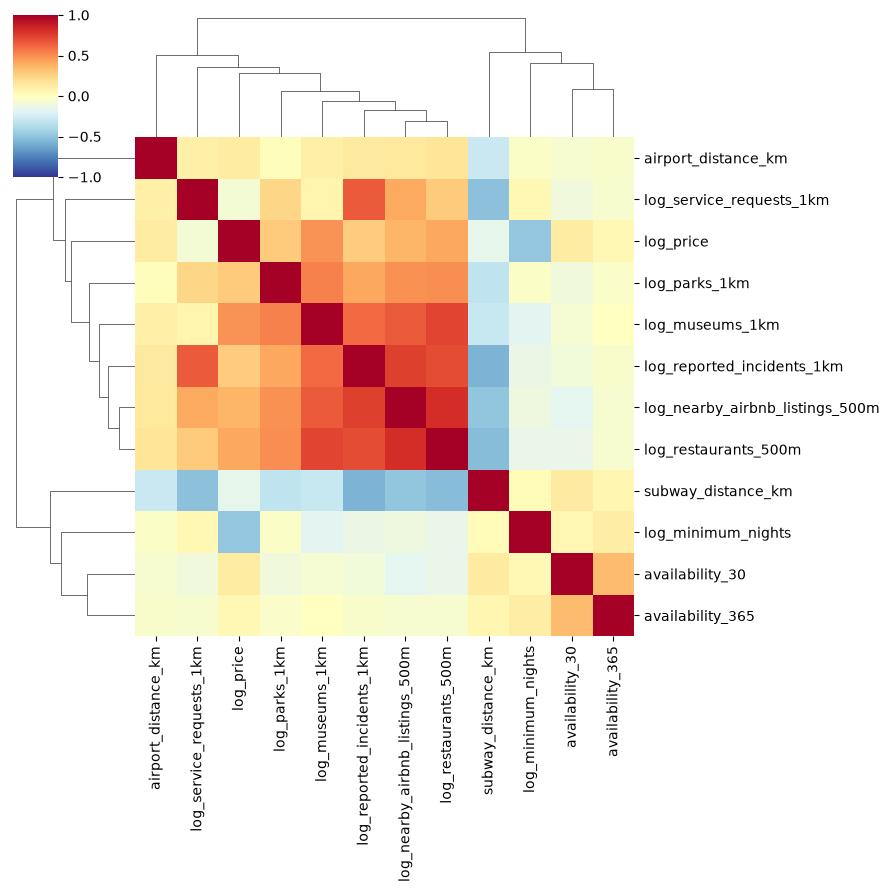

In [22]:
# Correlation between attributes (Demo 06)
cor = airbnb_st.corr()
sns.clustermap(cor,annot=False,cmap='RdYlBu_r',
               vmin=-1,vmax=1,figsize=(9,9))
plt.savefig('figures/correlation_clustermap.png',dpi=150,bbox_inches='tight')
plt.show()

## Step 21. Apply PCA — Demo 06

`n_components=None` lets PCA calculate all components first. `random_state=2000` preserves the professor's reproducible setting.

In [23]:
from sklearn.decomposition import PCA

pca = PCA(random_state = 2000, n_components = None)
pca.fit_transform(airbnb_st)

print('Eigenvalues:',pca.explained_variance_)
print('Explained variance ratio:',pca.explained_variance_ratio_)

Eigenvalues: [4.39999309 1.6451143  1.34033742 1.0775349  0.9108959  0.64386486
 0.58775832 0.47099314 0.36850239 0.26859747 0.16817552 0.11885108]
Explained variance ratio: [0.3666472  0.13708579 0.11168903 0.08978995 0.07590408 0.05365264
 0.04897734 0.03924741 0.03070695 0.02238197 0.0140139  0.00990375]


## Step 22. Explained variance, scree plot, and cumulative plot

Report the explained variance ratio for **every PC**. In the bar/step chart we follow the `explained_variance_ratio_plot` style from Demo 06. We also save separate scree and cumulative plots because the assignment specifically requests both.

In [24]:
exp_variance_ratio = pca.explained_variance_ratio_
variance_table = pd.DataFrame({
    'PC':['PC'+str(i) for i in range(1,len(exp_variance_ratio)+1)],
    'Explained Variance Ratio':exp_variance_ratio,
    'Cumulative Variance':np.cumsum(exp_variance_ratio)
})
print(variance_table.round(4).to_string(index=False))
variance_table.to_csv('data/pca_explained_variance.csv',index=False)

  PC  Explained Variance Ratio  Cumulative Variance
 PC1                    0.3666               0.3666
 PC2                    0.1371               0.5037
 PC3                    0.1117               0.6154
 PC4                    0.0898               0.7052
 PC5                    0.0759               0.7811
 PC6                    0.0537               0.8348
 PC7                    0.0490               0.8837
 PC8                    0.0392               0.9230
 PC9                    0.0307               0.9537
PC10                    0.0224               0.9761
PC11                    0.0140               0.9901
PC12                    0.0099               1.0000


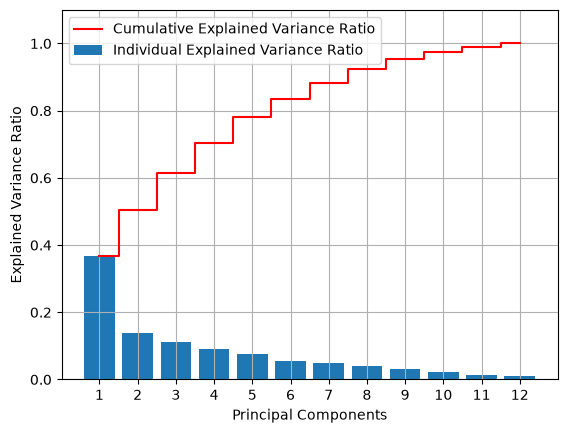

In [25]:
def explained_variance_ratio_plot(exp_variance_ratio):
    x_axis = range(1,len(exp_variance_ratio)+1)
    plt.bar(x_axis,exp_variance_ratio,align='center',
            label='Individual Explained Variance Ratio')
    plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',
             color='red',label='Cumulative Explained Variance Ratio')
    plt.ylim(0,1.1)
    plt.xticks(x_axis)
    plt.xlabel('Principal Components')
    plt.ylabel('Explained Variance Ratio')
    plt.legend()
    plt.grid()
    plt.savefig('figures/explained_variance_combined.png',dpi=150,bbox_inches='tight')
    plt.show()

explained_variance_ratio_plot(exp_variance_ratio)

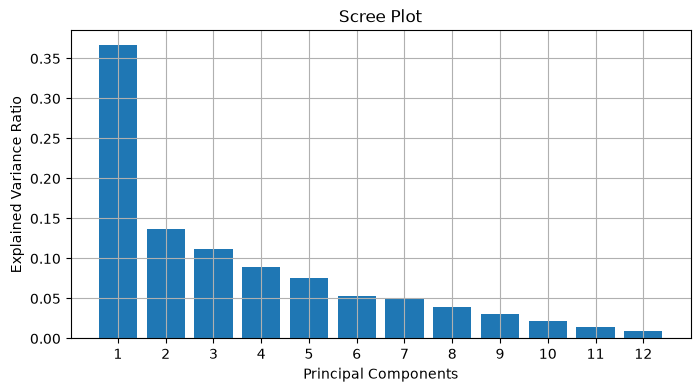

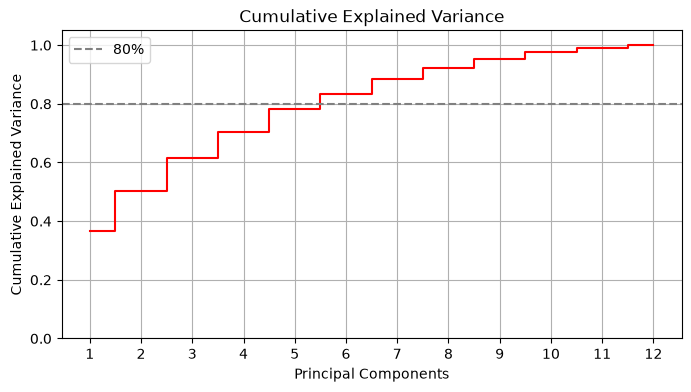

Components retained (at least 80%): 6


In [26]:
x_axis = range(1,len(exp_variance_ratio)+1)

# Scree plot
plt.figure(figsize=(8,4))
plt.bar(x_axis,exp_variance_ratio)
plt.xticks(x_axis)
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid()
plt.savefig('figures/scree_plot.png',dpi=150,bbox_inches='tight')
plt.show()

# Cumulative explained variance plot
plt.figure(figsize=(8,4))
plt.step(x_axis,np.cumsum(exp_variance_ratio),where='mid',color='red')
plt.axhline(.80,color='gray',linestyle='--',label='80%')
plt.xticks(x_axis)
plt.ylim(0,1.05)
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Cumulative Explained Variance')
plt.legend()
plt.grid()
plt.savefig('figures/cumulative_explained_variance.png',dpi=150,bbox_inches='tight')
plt.show()

retained = int(np.searchsorted(np.cumsum(exp_variance_ratio),.80)+1)
print('Components retained (at least 80%):',retained)

## Step 23. Component loadings — Demo 06

The loading matrix shows which original variables contribute most strongly to each PC. We interpret the largest **absolute** values; positive and negative signs describe directions, not better/worse outcomes.

In [27]:
loadings = pca.components_
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
loadings_df = pd.DataFrame.from_dict(dict(zip(pc_list,loadings)))
loadings_df['variable'] = airbnb_pca.columns.values
loadings_df = loadings_df.set_index('variable')

print(loadings_df.round(3).to_string())
loadings_df.to_csv('data/pca_loadings.csv')

                                   PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8    PC9   PC10   PC11   PC12
variable                                                                                                           
log_price                        0.233  0.544 -0.062  0.185 -0.073 -0.079  0.107 -0.128  0.743 -0.140  0.031  0.015
availability_30                 -0.085  0.283  0.599  0.170 -0.154 -0.636 -0.193 -0.014 -0.206  0.119 -0.022 -0.035
availability_365                -0.043  0.188  0.672  0.069  0.053  0.673  0.220  0.034 -0.031  0.019  0.018  0.011
log_minimum_nights              -0.105 -0.425  0.360 -0.315  0.520 -0.170 -0.178 -0.100  0.466 -0.139  0.018  0.039
log_nearby_airbnb_listings_500m  0.420 -0.016  0.023 -0.096  0.040  0.103 -0.267  0.060  0.109  0.611 -0.585 -0.023
log_restaurants_500m             0.422  0.061  0.001 -0.086  0.140  0.068 -0.252 -0.186 -0.100  0.314  0.748 -0.141
log_parks_1km                    0.302  0.055  0.050 -0.363  0.175 -0.29

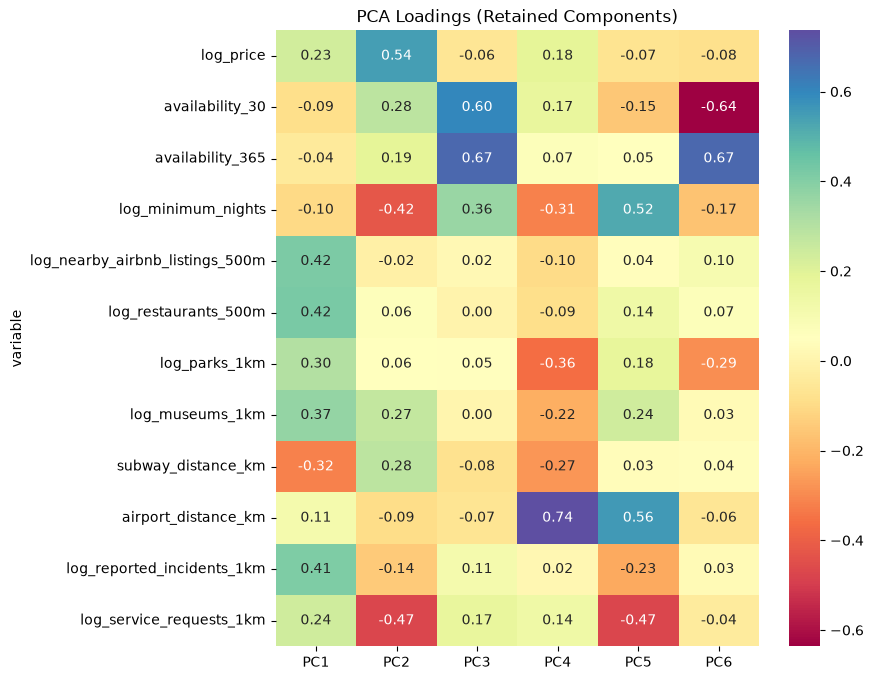

PC1 strongest loadings:
variable
log_restaurants_500m               0.422326
log_nearby_airbnb_listings_500m    0.419733
log_reported_incidents_1km         0.414158
log_museums_1km                    0.369391
Name: PC1, dtype: float64
PC2 strongest loadings:
variable
log_price                   0.543656
log_service_requests_1km    0.470295
log_minimum_nights          0.424709
subway_distance_km          0.283229
Name: PC2, dtype: float64
PC3 strongest loadings:
variable
availability_365            0.672175
availability_30             0.599063
log_minimum_nights          0.360422
log_service_requests_1km    0.170807
Name: PC3, dtype: float64
PC4 strongest loadings:
variable
airport_distance_km    0.736299
log_parks_1km          0.362904
log_minimum_nights     0.314862
subway_distance_km     0.273884
Name: PC4, dtype: float64
PC5 strongest loadings:
variable
airport_distance_km         0.557563
log_minimum_nights          0.520349
log_service_requests_1km    0.471101
log_museums_1km     

In [28]:
plt.figure(figsize=(max(7,retained*1.3),8))
ax = sns.heatmap(loadings_df.iloc[:,:retained],annot=True,
                 fmt='.2f',cmap='Spectral')
plt.title('PCA Loadings (Retained Components)')
plt.savefig('figures/pca_loadings_heatmap.png',dpi=150,bbox_inches='tight')
plt.show()

for pc in pc_list[:retained]:
    print(pc,'strongest loadings:')
    print(loadings_df[pc].abs().sort_values(ascending=False).head(4))

## Step 24. PCA scores and biplot — Demo 06

Scores locate each listing on the components. A biplot shows **PC1 versus PC2**, even if more components are kept for future analysis. We show 3,000 random listing points for readability; their PCA scores are calculated using **all priced listings**.

In [29]:
scores = pca.transform(airbnb_st).transpose()
num_pc = pca.components_.shape[1]
pc_list = ['PC'+str(i) for i in list(range(1,num_pc+1))]
scores_df = pd.DataFrame.from_dict(dict(zip(pc_list,scores)))
scores_df.insert(0,'listing_id',priced['id'].to_numpy())
scores_df.to_csv('data/pca_scores.csv',index=False)
print(scores_df.head())

            listing_id       PC1       PC2       PC3       PC4       PC5  \
0  1215930899551057941 -3.944838  1.658401  1.082562 -0.700747  0.573521   
1   791539646807027059 -0.104514 -0.253909  2.055099  0.146734 -0.276673   
2   984905638210475309 -4.168573  1.870173  1.032534 -1.012637  0.714008   
3             42220146 -1.878726 -0.917176  0.275056  2.308365  0.806366   
4             42220001 -1.830414 -0.677742  0.233718  2.348734  0.827820   

        PC6       PC7       PC8       PC9      PC10      PC11      PC12  
0 -0.284254  0.391367 -0.437458 -0.109243 -0.051113  0.388471  0.033684  
1 -1.049580  2.026177  0.454472  0.315167  0.153234  0.406498  0.086542  
2 -0.387935  0.476800 -0.479074 -0.332235  0.089553  0.495974  0.050234  
3 -1.337010 -0.578304 -0.362254 -0.399129 -0.207503  0.785307 -0.608342  
4 -1.347926 -0.598217 -0.266359 -0.108457 -0.157501  0.604124 -0.551542  


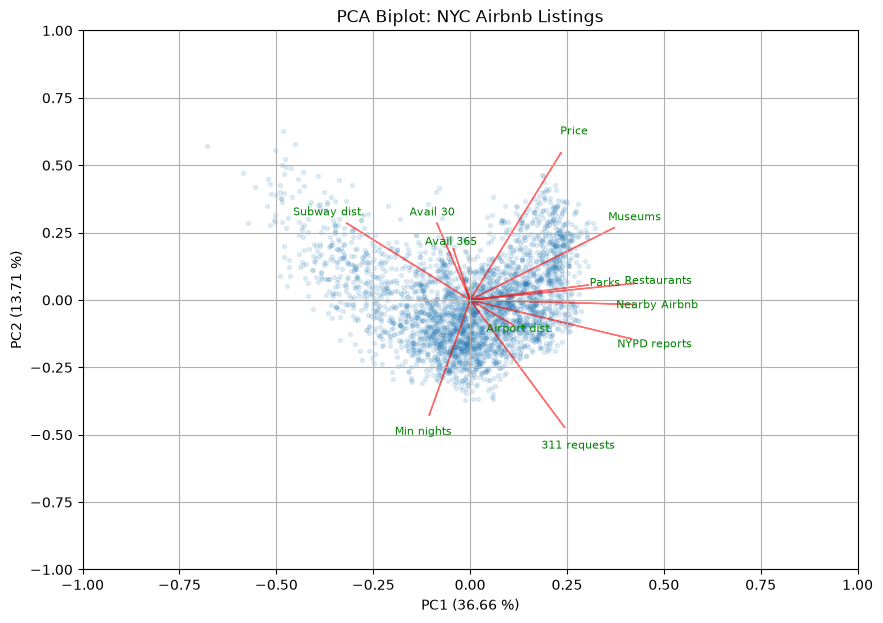

In [30]:
# Biplot based on the instructor's Demo 06 function
def biplot(score,coeff,pcax,pcay,labels=None):
    pca1 = pcax - 1
    pca2 = pcay - 1
    xs = score[:,pca1]
    ys = score[:,pca2]
    scalex = 1.0/(xs.max()-xs.min())
    scaley = 1.0/(ys.max()-ys.min())
    plt.figure(figsize=(10,7))
    plt.scatter(xs*scalex,ys*scaley,alpha=.12,s=8)
    n = coeff.shape[0]
    for i in range(n):
        plt.arrow(0,0,coeff[i,pca1],coeff[i,pca2],color='r',alpha=.5)
        label = 'Var'+str(i+1) if labels is None else labels[i]
        plt.text(coeff[i,pca1]*1.15,coeff[i,pca2]*1.15,
                 label,color='g',ha='center',va='center',fontsize=8)
    plt.xlim(-1,1)
    plt.ylim(-1,1)
    plt.xlabel(f'PC{pcax} ({pca.explained_variance_ratio_[pca1]*100:.2f} %)')
    plt.ylabel(f'PC{pcay} ({pca.explained_variance_ratio_[pca2]*100:.2f} %)')
    plt.title('PCA Biplot: NYC Airbnb Listings')
    plt.grid()
    plt.savefig('figures/pca_biplot.png',dpi=150,bbox_inches='tight')
    plt.show()

scores = pca.transform(airbnb_st)
np.random.seed(2000)
sample_ids = np.random.choice(len(scores),size=min(3000,len(scores)),replace=False)
short_names = ['Price','Avail 30','Avail 365','Min nights',
               'Nearby Airbnb','Restaurants','Parks','Museums',
               'Subway dist.','Airport dist.','NYPD reports','311 requests']
biplot(scores[sample_ids],pca.components_.T,1,2,labels=short_names)

## Step 25. Interpretation, audience discussion, and limitations

### Component selection
| Component | Eigenvalue | Explained variance | Cumulative |
|---|---|---|---|
| PC1 | 4.40 | 36.7% | 36.7% |
| PC2 | 1.65 | 13.7% | 50.4% |
| PC3 | 1.34 | 11.2% | 61.5% |
| PC4 | 1.08 | 9.0% | 70.5% |
| PC5 | 0.91 | 7.6% | 78.1% |
| PC6 | 0.64 | 5.4% | 83.5% |
| PC7–PC12 | 0.59 → 0.12 | 4.9% → 1.0% | 88.4% → 100% |

We retain **6 components**, the smallest number that explains **at least 80%** of the variance (83.5%). For comparison, the eigenvalue > 1 rule would keep 4 components (70.5%). The scree plot drops sharply after PC1 and flattens after about PC6, so 6 components keep most of the information while reducing 12 variables to half. The biplot shows only PC1 and PC2, but all 6 retained components can be used in the next session.

### What the major components represent
- **PC1 (36.7%) – Busy, central neighborhood vs. quiet outer area.** High: restaurants within 500 m (0.42), nearby Airbnb listings (0.42), NYPD reports (0.41), museums (0.37) and parks (0.30); low: distance to the subway (−0.32).
- **PC2 (13.7%) – Higher-priced short stays vs. monthly rentals in noisier residential areas.** High: price (0.54); low: residential noise complaints (−0.47) and minimum nights (−0.42).
- **PC3 (11.2%) – How open the calendar is.** High: availability in the next 365 days (0.67) and 30 days (0.60), with longer minimum stays (0.36).
- **PC4 (9.0%) – Distance from airports.** Mainly airport distance (0.74), with fewer parks nearby (−0.36).
- **PC5 (7.6%)** mixes airport distance (0.56), longer minimum stays (0.52) and fewer noise complaints (−0.47).
- **PC6 (5.4%)** contrasts long-term availability (`availability_365`, 0.67) with near-term availability (`availability_30`, −0.64).

### Biplot (PC1 vs PC2)
- The neighborhood-activity arrows (restaurants, nearby Airbnb listings, NYPD reports, parks, museums) point to the right, and subway distance points to the left, so PC1 is one "urban activity" direction.
- Price points up and to the right, while minimum nights and residential noise complaints point down.
- The points form one continuous cloud: denser on the right (central neighborhoods) and more spread out on the left (outer areas far from the subway).
- **These are directions of variation, not clusters.** Dense or sparse areas in the plot are not confirmed groups.

### Relation to the research question and audience
For **current and prospective NYC Airbnb hosts and small short-term-rental property managers**, listings differ mainly in (1) how busy and central the surrounding neighborhood is, (2) whether the listing is a higher-priced short stay or a lower-priced monthly rental, and (3) how open its calendar is. A host can compare a listing with others in a similar neighborhood setting instead of comparing price alone. In the next session, the retained components will be used to group listings, and room type, borough, host listing count and license status will help explain the groups.

### Limitations
- 10,512 listings (35.1%) without a price are excluded; almost all of them have no availability in the next year, so the PCA describes **actively offered listings** only.
- Unavailable calendar dates may be booked **or** blocked by the host.
- The 311 data contain only **Noise - Residential** complaints, and NYPD reports are reported incidents, not an objective safety score.
- CommonPlace and restaurant data are November 2026 snapshots, slightly later than the September 2026 Airbnb data.
- Airbnb coordinates are slightly shifted for privacy, so nearby counts are approximate.
- No clustering or classification was performed.